In [2]:
import torch
import numpy as np
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

In [ ]:
torch.manual_seed(42)

In [4]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [5]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

In [6]:
train_dataset = torchvision.datasets.MNIST(
    root="/home/abubakr/Desktop/projects/handwritten_digit_mnist/data",
    train=True,
    download=True,
    transform=transform
)

In [7]:
image_tensor, label = train_dataset[0] # the first image

print(f"Image type: {type(image_tensor)}")
print(f"Image shape: {image_tensor.shape}")
print(f"Label type: {type(label)}")
print(f"Label value: {label}")

Image type: <class 'torch.Tensor'>
Image shape: torch.Size([1, 28, 28])
Label type: <class 'int'>
Label value: 5


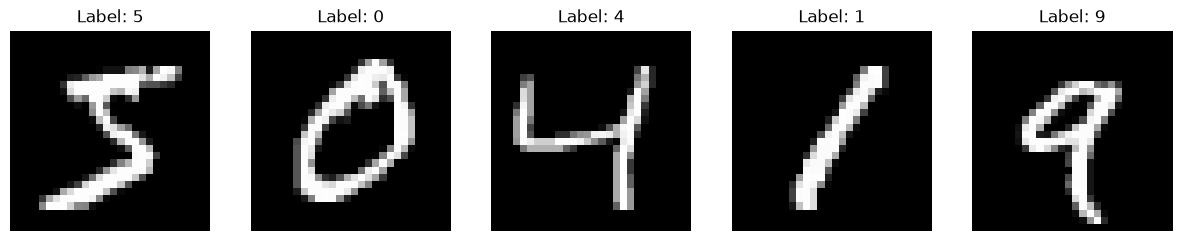

In [14]:
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    image_tensor, label = train_dataset[i]
    image_matrix = image_tensor[0]
    ax[i].imshow(image_matrix, cmap='gray')
    ax[i].set_title(label=f"Label: {label}")
    ax[i].axis('off')
plt.show()


In [9]:
test_dataset = torchvision.datasets.MNIST(
    root="/home/abubakr/Desktop/projects/handwritten_digit_mnist/data",
    train=False,
    download=True,
    transform=transform
)

In [18]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

In [24]:
print(f"Total Number of Batches: {len(train_loader)}")
print(f"Total Individual Samples: {len(train_loader.dataset)}")
print(f"Configured Batch Size: {train_loader.batch_size}")

Total Number of Batches: 938
Total Individual Samples: 60000
Configured Batch Size: 64
